# Electricity consumption: exploration and cleaning

Single notebook combining the exploratory analysis and the cleaning steps.


## Import deps and load dataset

In [1]:
import datetime

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import src.utils.preprocess as preproc


In [2]:
# load dataset
data = preproc.load_data_set(
    "https://simplonline-v3-prod.s3.eu-west-3.amazonaws.com/media/file/csv/dataset-electric-6b0361bc9dd9f506891054.csv"
)
data.columns


Index(['Datetime', 'Consumption'], dtype='str')

## Dataset overview

In [3]:
data.info()
data.describe()
data.shape
data.head(3)
# the observations are 1h apart, so we can derive the period covered by the data


<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Datetime     145366 non-null  str    
 1   Consumption  145366 non-null  float64
dtypes: float64(1), str(1)
memory usage: 2.2 MB


,Datetime,Consumption
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0


In [4]:
data.isna().sum()
# no NaN values: the data covers 145366 hours, which is equivalent to 15.006 years
data.duplicated().sum()


np.int64(0)

In [5]:
data.iloc[-1]

Datetime       2018-01-02 00:00:00
Consumption                38608.0
Name: 145365, dtype: object

## Data quality: sampling and gaps

In [6]:
# read-only diagnostics: this cell does not modify `data`
# sort first: the raw file is not chronologically ordered
timestamps = pd.to_datetime(data["Datetime"]).sort_values()

print("Sampling interval value counts:")
print(timestamps.diff().value_counts().to_string())

full_range = pd.date_range(timestamps.min(), timestamps.max(), freq="h")
missing_hours = full_range.difference(pd.DatetimeIndex(timestamps))

print()
print("Duplicated timestamps:", timestamps.duplicated().sum())
print("Missing hours:", len(missing_hours))
missing_hours


Sampling interval value counts:
Datetime
0 days 01:00:00      139275
-2 days +01:00:00      6040
0 days 02:00:00          29
729 days 01:00:00         8
728 days 01:00:00         7
0 days 00:00:00           4
-2 days +02:00:00         1
577 days 01:00:00         1

Duplicated timestamps: 4
Missing hours: 30


DatetimeIndex(['2002-04-07 03:00:00', '2002-10-27 02:00:00',
               '2003-04-06 03:00:00', '2003-10-26 02:00:00',
               '2004-04-04 03:00:00', '2004-10-31 02:00:00',
               '2005-04-03 03:00:00', '2005-10-30 02:00:00',
               '2006-04-02 03:00:00', '2006-10-29 02:00:00',
               '2007-03-11 03:00:00', '2007-11-04 02:00:00',
               '2008-03-09 03:00:00', '2008-11-02 02:00:00',
               '2009-03-08 03:00:00', '2009-11-01 02:00:00',
               '2010-03-14 03:00:00', '2010-11-07 02:00:00',
               '2010-12-10 00:00:00', '2011-03-13 03:00:00',
               '2011-11-06 02:00:00', '2012-03-11 03:00:00',
               '2012-11-04 02:00:00', '2013-03-10 03:00:00',
               '2013-11-03 02:00:00', '2014-03-09 03:00:00',
               '2015-03-08 03:00:00', '2016-03-13 03:00:00',
               '2017-03-12 03:00:00', '2018-03-11 03:00:00'],
              dtype='datetime64[us]', freq=None)

## Cleaning: datetime and ordering

In [7]:
data = preproc.convert_to_date_time(data, "Datetime")

In [8]:
preproc.is_ordered(data, "Datetime")

False

In [9]:
data = preproc.fix_chrono_order(data, "Datetime")

In [10]:
preproc.is_ordered(data, "Datetime")

True

In [11]:
data = preproc.set_index(data, "Datetime")
print(data.index.dtype)

datetime64[us]


## Distribution of consumption

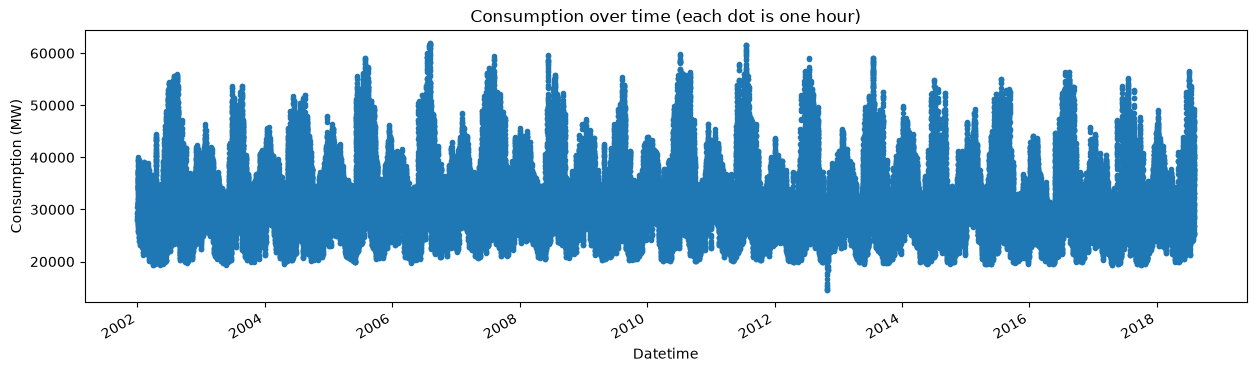

In [12]:
fig, ax = plt.subplots(figsize=(15, 4))
data["Consumption"].plot(
    style=".",
    ax=ax,
    title="Consumption over time (each dot is one hour)",
    ylabel="Consumption (MW)",
)
plt.show()


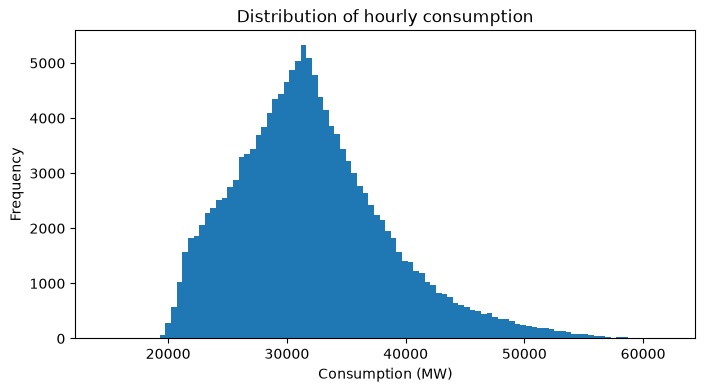

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
data["Consumption"].plot(
    kind="hist", bins=100, ax=ax, title="Distribution of hourly consumption"
)
ax.set_xlabel("Consumption (MW)")
plt.show()


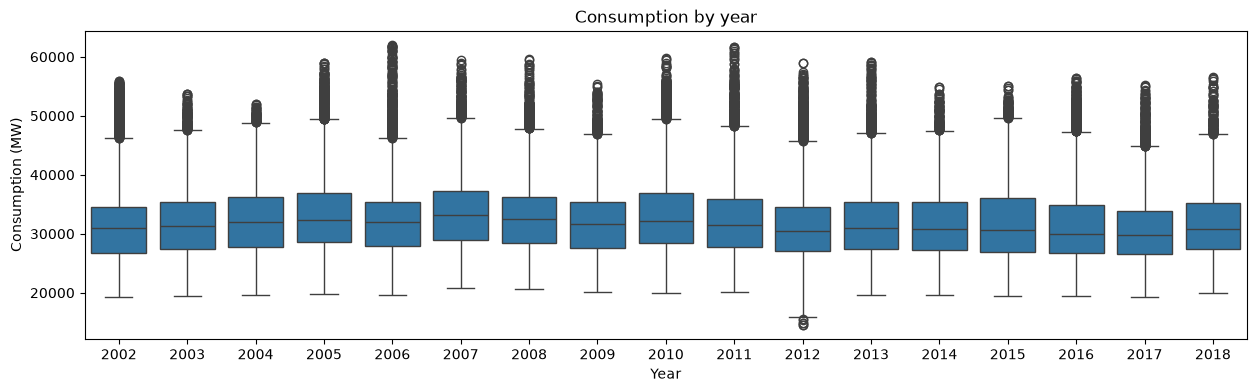

In [14]:
fig, ax = plt.subplots(figsize=(15, 4))
sns.boxplot(x=data.index.year, y=data["Consumption"], ax=ax)
ax.set_title("Consumption by year")
ax.set_xlabel("Year")
ax.set_ylabel("Consumption (MW)")
plt.show()


## Daily cycle

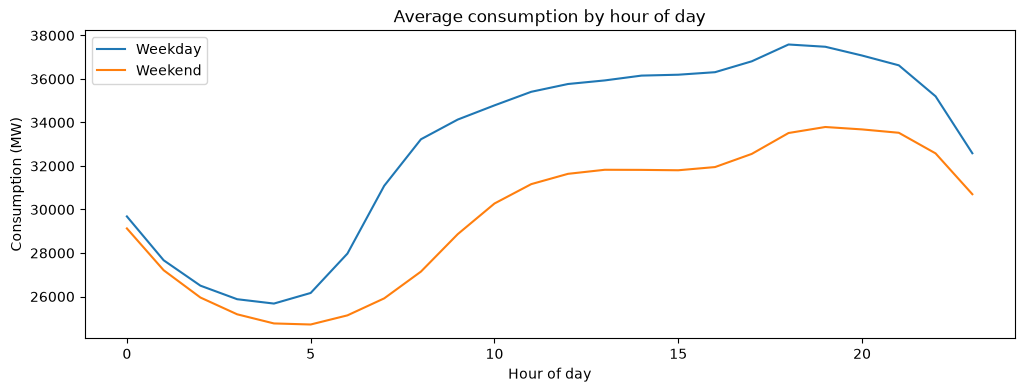

In [15]:
profile = (
    data.groupby([data.index.hour, data.index.day_of_week >= 5])["Consumption"]
    .mean()
    .unstack()
)
profile.columns = ["Weekday", "Weekend"]

fig, ax = plt.subplots(figsize=(12, 4))
profile.plot(ax=ax, title="Average consumption by hour of day")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Consumption (MW)")
plt.show()


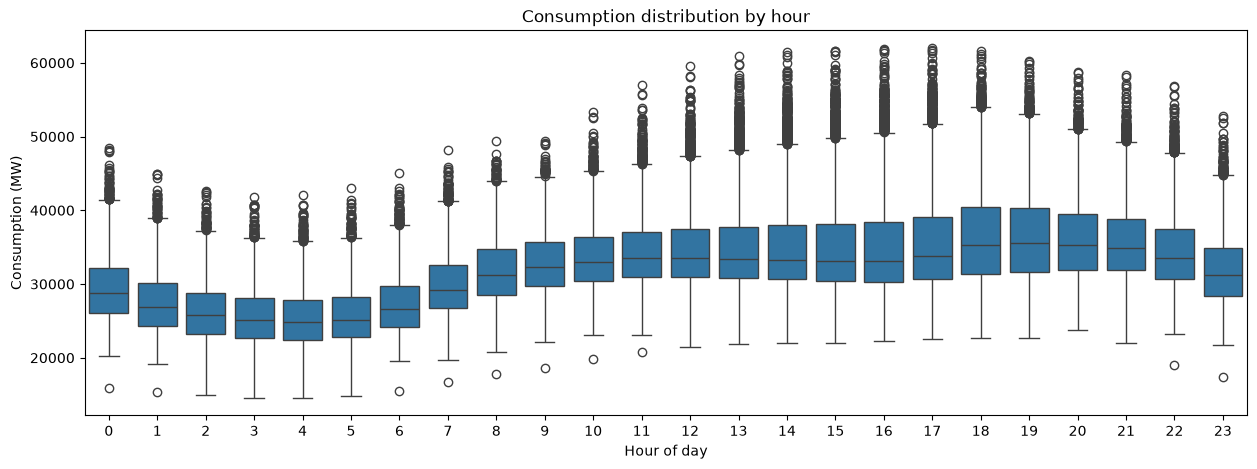

In [16]:
fig, ax = plt.subplots(figsize=(15, 5))
sns.boxplot(x=data.index.hour, y=data["Consumption"], ax=ax)
ax.set_title("Consumption distribution by hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Consumption (MW)")
plt.show()


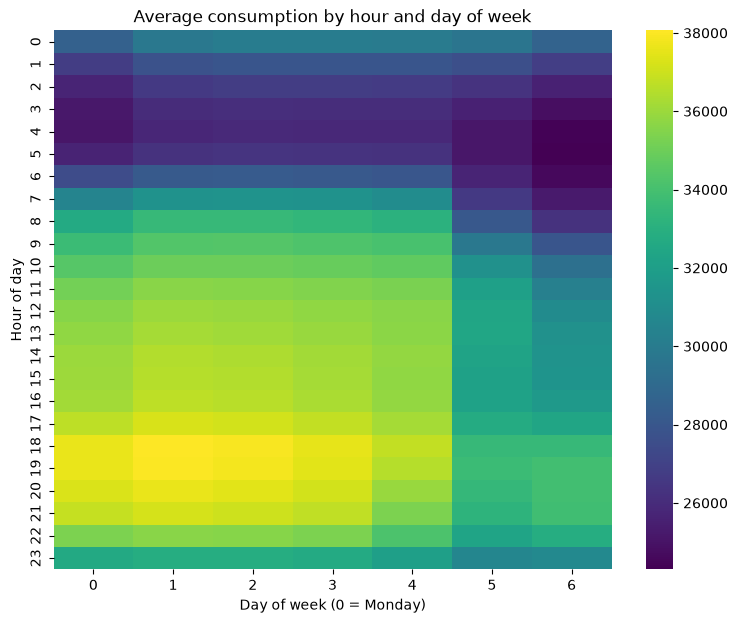

In [17]:
pivot_hour_weekday = data.pivot_table(
    index=data.index.hour,
    columns=data.index.day_of_week,
    values="Consumption",
    aggfunc="mean",
)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(pivot_hour_weekday, cmap="viridis", ax=ax)
ax.set_title("Average consumption by hour and day of week")
ax.set_xlabel("Day of week (0 = Monday)")
ax.set_ylabel("Hour of day")
plt.show()


## Weekly and seasonal cycle

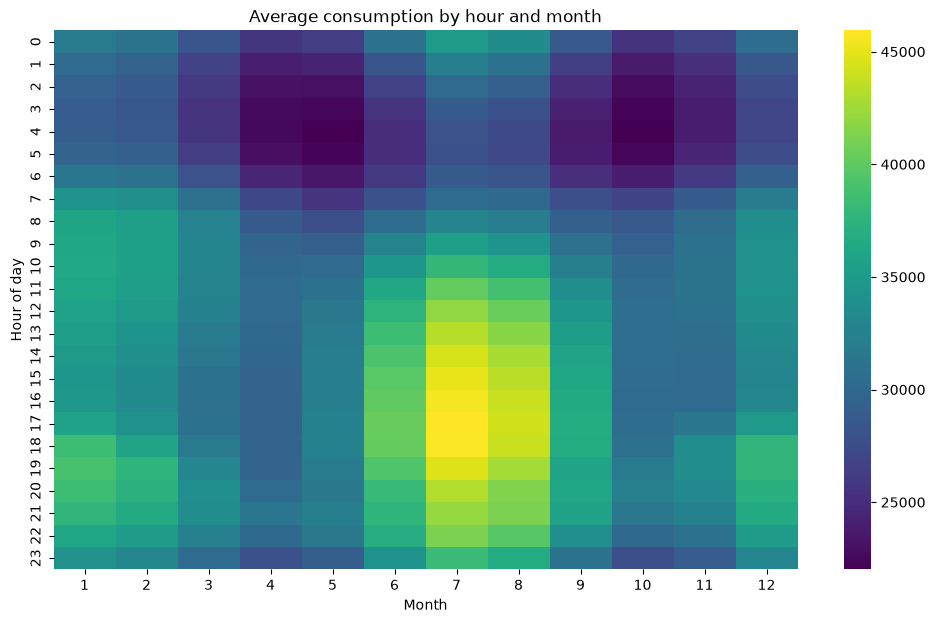

In [18]:
pivot_hour_month = data.pivot_table(
    index=data.index.hour,
    columns=data.index.month,
    values="Consumption",
    aggfunc="mean",
)

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(pivot_hour_month, cmap="viridis", ax=ax)
ax.set_title("Average consumption by hour and month")
ax.set_xlabel("Month")
ax.set_ylabel("Hour of day")
plt.show()


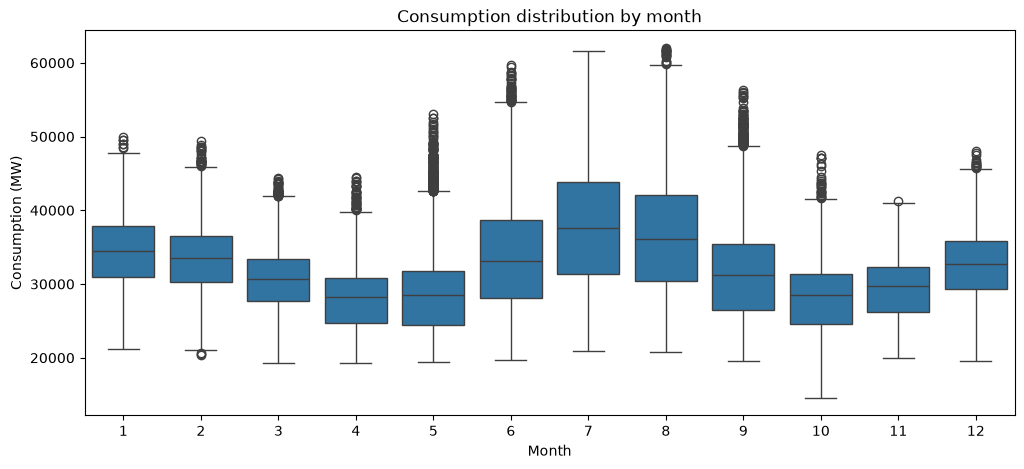

In [19]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(x=data.index.month, y=data["Consumption"], ax=ax)
ax.set_title("Consumption distribution by month")
ax.set_xlabel("Month")
ax.set_ylabel("Consumption (MW)")
plt.show()


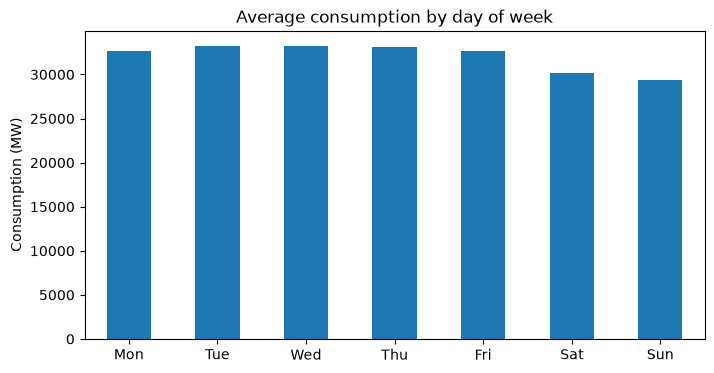

In [20]:
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 4))
data.groupby(data.index.day_of_week)["Consumption"].mean().plot(
    kind="bar", ax=ax, title="Average consumption by day of week"
)
ax.set_xticks(range(7), weekday_names, rotation=0)
ax.set_xlabel("")
ax.set_ylabel("Consumption (MW)")
plt.show()


## Zooming in: a week, a month, a year

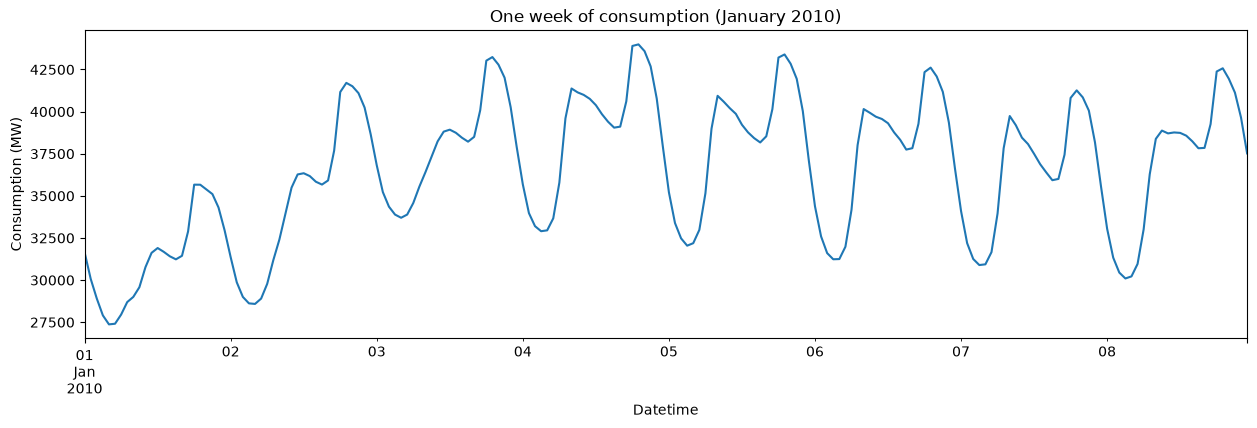

In [21]:
fig, ax = plt.subplots(figsize=(15, 4))
data.loc["2010-01-01":"2010-01-08", "Consumption"].plot(
    ax=ax, title="One week of consumption (January 2010)"
)
ax.set_ylabel("Consumption (MW)")
plt.show()


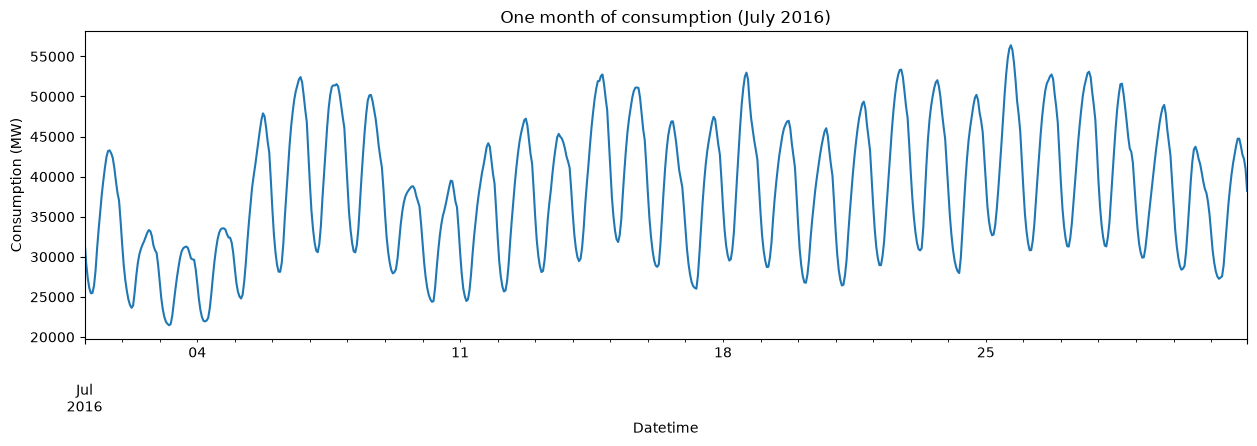

In [22]:
fig, ax = plt.subplots(figsize=(15, 4))
data.loc["2016-07", "Consumption"].plot(
    ax=ax, title="One month of consumption (July 2016)"
)
ax.set_ylabel("Consumption (MW)")
plt.show()


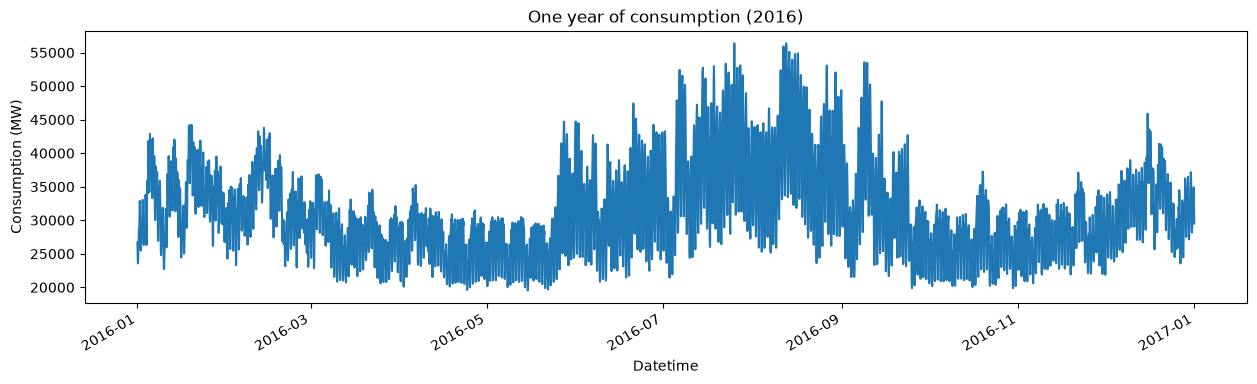

In [23]:
fig, ax = plt.subplots(figsize=(15, 4))
data.loc["2016", "Consumption"].plot(
    ax=ax, title="One year of consumption (2016)"
)
ax.set_ylabel("Consumption (MW)")
plt.show()


## Variance over time

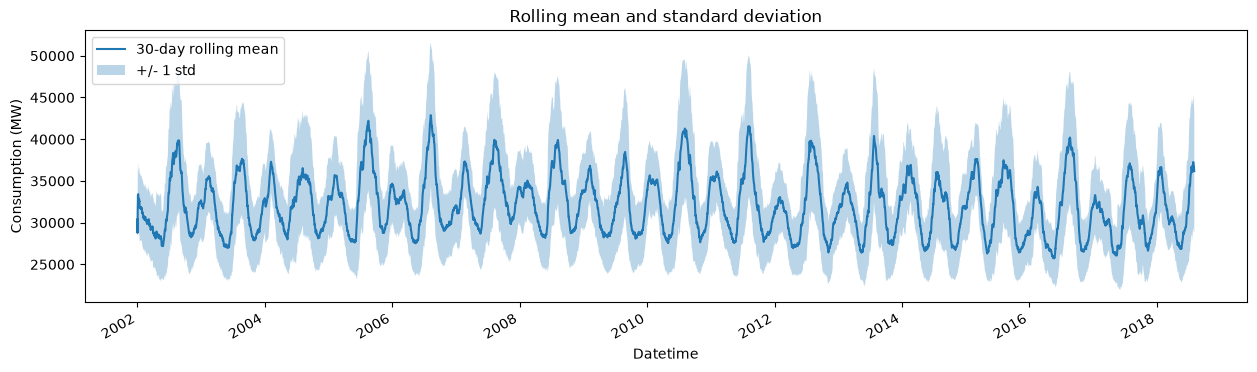

In [24]:
rolling = data["Consumption"].rolling("30D")

fig, ax = plt.subplots(figsize=(15, 4))
rolling.mean().plot(ax=ax, label="30-day rolling mean")
ax.fill_between(
    rolling.mean().index,
    rolling.mean() - rolling.std(),
    rolling.mean() + rolling.std(),
    alpha=0.3,
    label="+/- 1 std",
)
ax.set_title("Rolling mean and standard deviation")
ax.set_ylabel("Consumption (MW)")
ax.legend()
plt.show()


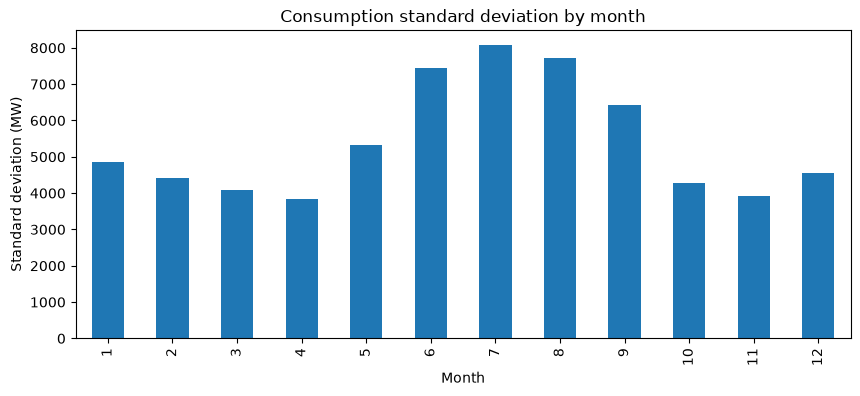

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
data.groupby(data.index.month)["Consumption"].std().plot(
    kind="bar", ax=ax, title="Consumption standard deviation by month"
)
ax.set_xlabel("Month")
ax.set_ylabel("Standard deviation (MW)")
plt.show()


## Autocorrelation

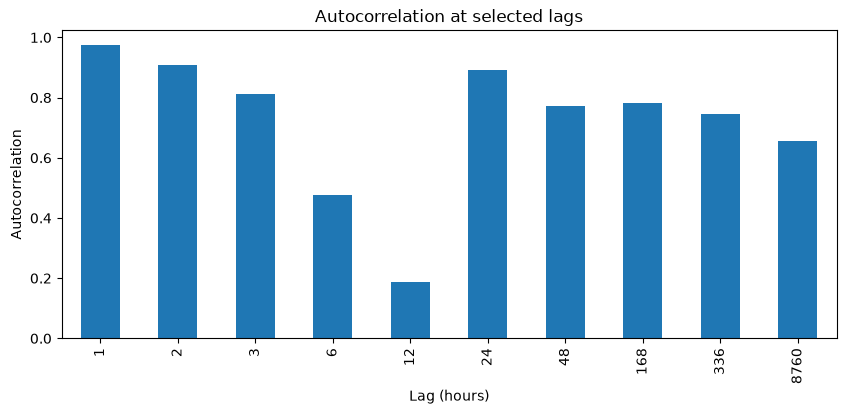

In [26]:
lags = [1, 2, 3, 6, 12, 24, 48, 168, 336, 8760]
acf = pd.Series({lag: data["Consumption"].autocorr(lag) for lag in lags})

fig, ax = plt.subplots(figsize=(10, 4))
acf.plot(kind="bar", ax=ax, title="Autocorrelation at selected lags")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
plt.show()


## Anomaly detection

In [27]:
data = preproc.flag_anomalies(data, "Consumption")
data["is_anomaly"].sum()

np.int64(818)

## Distribution visualisation

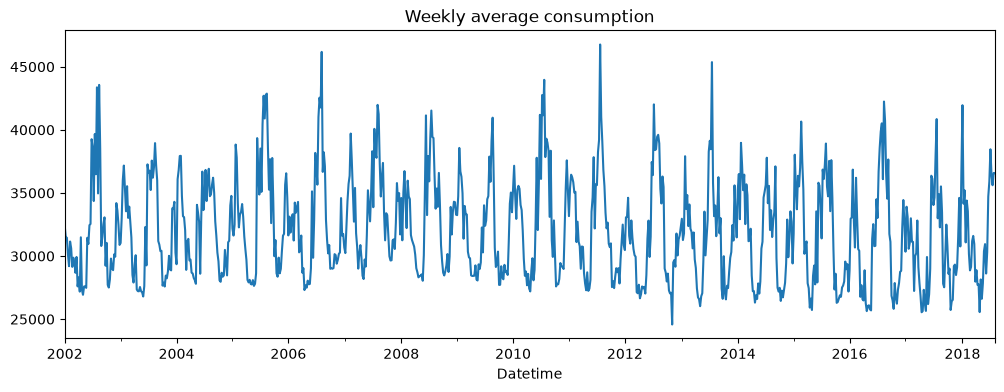

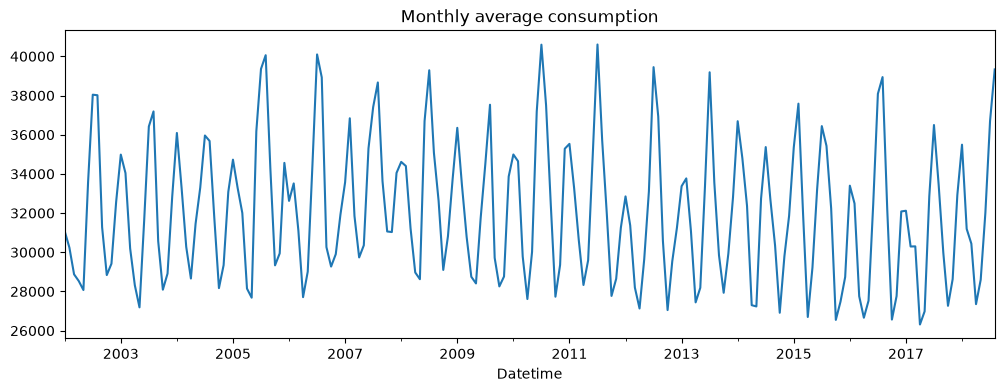

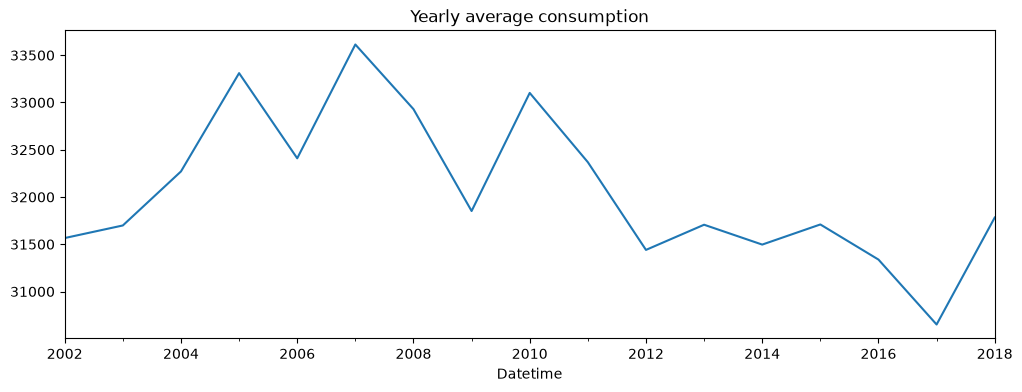

In [28]:
# weekly
data["Consumption"].resample("W").mean().plot(figsize=(12, 4), title="Weekly average consumption")
plt.show()

# monthly
data["Consumption"].resample("MS").mean().plot(figsize=(12, 4), title="Monthly average consumption")
plt.show()

# yearly
data["Consumption"].resample("YS").mean().plot(figsize=(12, 4), title="Yearly average consumption")
plt.show()


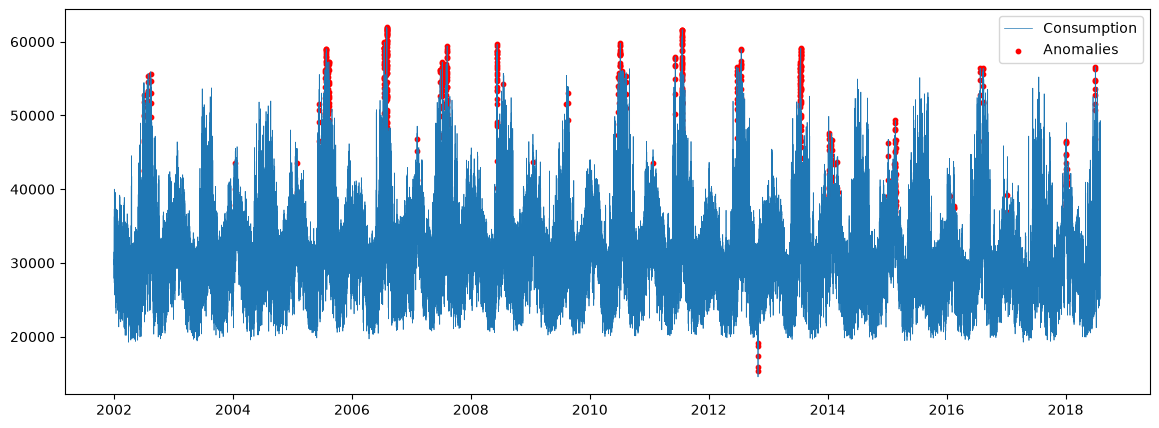

In [29]:
anomalies = data[data["is_anomaly"]]

plt.figure(figsize=(14, 5))
plt.plot(data.index, data["Consumption"], label="Consumption", linewidth=0.5)
plt.scatter(anomalies.index, anomalies["Consumption"], color="red", s=10, label="Anomalies")
plt.legend()
plt.show()


## Outliers and events

In [30]:
daily_mean = data["Consumption"].resample("D").mean()

print("Highest-consumption days:")
print(daily_mean.nlargest(5).round(0).to_string())
print()
print("Lowest-consumption days:")
print(daily_mean.nsmallest(5).round(0).to_string())


Highest-consumption days:
Datetime
2006-08-02    52230.0
2011-07-22    51987.0
2006-08-03    51824.0
2006-08-01    50225.0
2013-07-19    49271.0

Lowest-consumption days:
Datetime
2012-10-30    19769.0
2016-04-24    22737.0
2016-05-08    22874.0
2002-03-31    23000.0
2013-05-26    23074.0


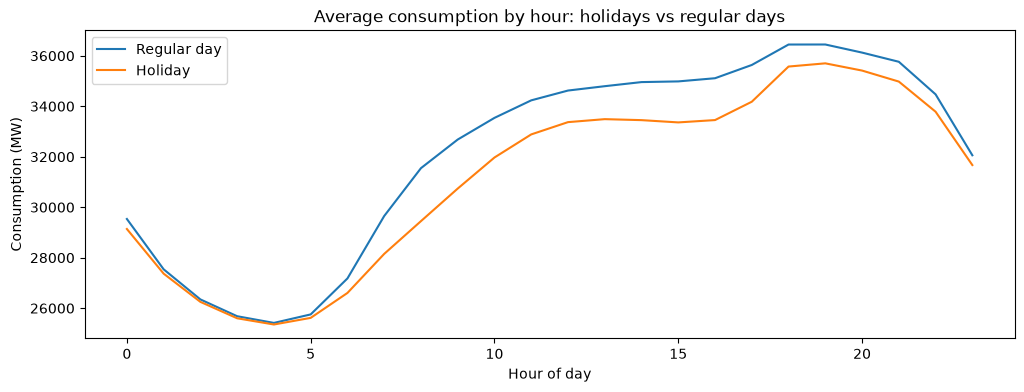

In [31]:
from pandas.tseries.holiday import USFederalHolidayCalendar

holidays = USFederalHolidayCalendar().holidays(
    start=data.index.min(), end=data.index.max()
)
is_holiday = data.index.normalize().isin(holidays)

holiday_profile = (
    data.assign(is_holiday=is_holiday)
    .groupby([data.index.hour, "is_holiday"])["Consumption"]
    .mean()
    .unstack()
)
holiday_profile.columns = ["Regular day", "Holiday"]

fig, ax = plt.subplots(figsize=(12, 4))
holiday_profile.plot(
    ax=ax, title="Average consumption by hour: holidays vs regular days"
)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Consumption (MW)")
plt.show()


In [32]:
jumps = data["Consumption"].diff()

print("Largest hour-to-hour drops:")
print(jumps.nsmallest(5).to_string())
print()
print("Largest hour-to-hour rises:")
print(jumps.nlargest(5).to_string())
print()
print("Consecutive identical values:", int((jumps == 0).sum()))


Largest hour-to-hour drops:
Datetime
2012-06-30 00:00:00   -6866.0
2008-06-10 00:00:00   -4925.0
2011-06-02 00:00:00   -4888.0
2007-06-27 23:00:00   -4810.0
2005-06-09 00:00:00   -4681.0

Largest hour-to-hour rises:
Datetime
2002-11-19 05:00:00    6326.0
2002-03-28 18:00:00    5629.0
2003-07-20 11:00:00    5115.0
2009-01-14 07:00:00    4606.0
2005-01-27 07:00:00    4596.0

Consecutive identical values: 54
